# Description
About Dataset
Netflix is a popular streaming service that offers a vast catalog of movies, TV shows, and original contents. This dataset is a cleaned version of the original version which can be found here. The data consist of contents added to Netflix from 2008 to 2021. The oldest content is as old as 1925 and the newest as 2021. This dataset will be prepared and cleaned with SQL and visualized with PowerBI. The purpose of this dataset is to test my data cleaning and visualization skills.

Instruments: SQL (MySQL+DataGrip), PowerBI. I used SQL instead of Python just for portfolio project.  

Project has:  
* data/ format preparations;  
* data cleaning;  
* check for hypothesis, normalization over wide distribution, common table expressions (CTE);  
* data visualization;  
* conclusion.  

In [16]:
print("jhi")

jhi


In [17]:
pip install pandas


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
import pandas as pd


# Preparation


In [19]:
dataset=pd.read_csv('netflix_titles.csv')
dataset

# description

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [20]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [21]:
dataset.shape

(8807, 12)

In [22]:
pip install matplotlib


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:
pip install seaborn 



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [24]:
import matplotlib.pyplot as plt

In [25]:
import seaborn as sns
import numpy as np

In [26]:
df = pd.read_csv("netflix_titles.csv")

In [27]:
missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(1)
print(missing.sort_values("missing", ascending=False))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate show_id:", df["show_id"].duplicated().sum())

              missing   pct
director         2634  29.9
country           831   9.4
cast              825   9.4
date_added         10   0.1
rating              4   0.0
duration            3   0.0
show_id             0   0.0
type                0   0.0
title               0   0.0
release_year        0   0.0
listed_in           0   0.0
description         0   0.0
Duplicate rows: 0
Duplicate show_id: 0


In [28]:
print(df[df["rating"].str.contains("min", na=False)][["title", "rating", "duration"]])
# Leading/trailing spaces in date_added
print("date_added with extra spaces:", (df["date_added"].dropna() != df["date_added"].dropna().str.strip()).sum())

                                     title  rating duration
5541                       Louis C.K. 2017  74 min      NaN
5794                 Louis C.K.: Hilarious  84 min      NaN
5813  Louis C.K.: Live at the Comedy Store  66 min      NaN
date_added with extra spaces: 88


In [29]:
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%B %d, %Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month
df["lag_years"] = df["year_added"] - df["release_year"]

type
Movie      0.696
TV Show    0.304
Name: proportion, dtype: float64


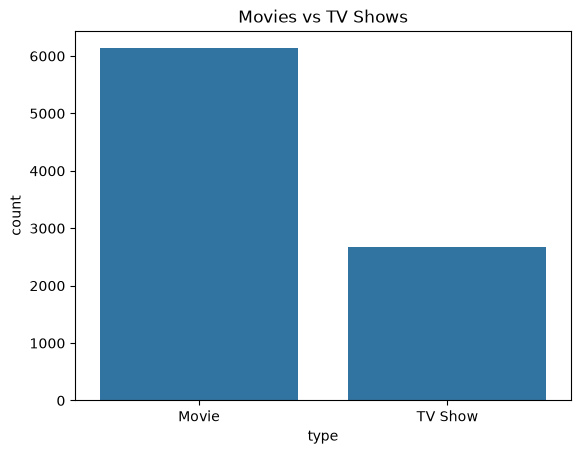

In [30]:
print(df["type"].value_counts(normalize=True).round(3))
sns.countplot(data=df, x="type")
plt.title("Movies vs TV Shows")
plt.show()

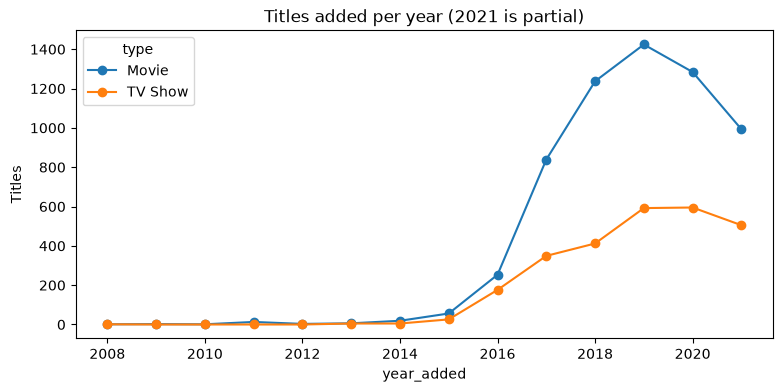

In [31]:
yearly = df.groupby(["year_added", "type"]).size().unstack(fill_value=0)
yearly.plot(kind="line", marker="o", figsize=(9, 4))
plt.title("Titles added per year (2021 is partial)")
plt.ylabel("Titles")
plt.show()

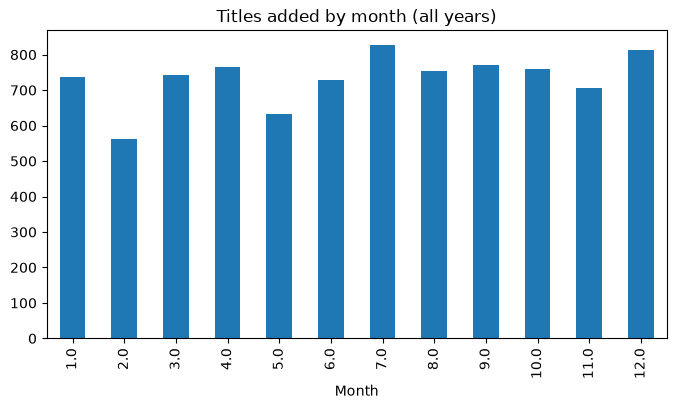

In [32]:
df["month_added"].value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
plt.title("Titles added by month (all years)")
plt.xlabel("Month")
plt.show()

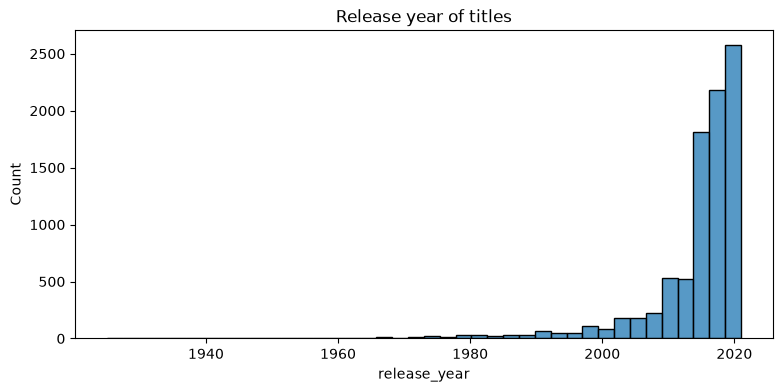

count    8807.000000
mean     2014.180198
std         8.819312
min      1925.000000
25%      2013.000000
50%      2017.000000
75%      2019.000000
max      2021.000000
Name: release_year, dtype: float64


In [33]:
plt.figure(figsize=(9, 4))
sns.histplot(df["release_year"], bins=40)
plt.title("Release year of titles")
plt.show()
print(df["release_year"].describe())

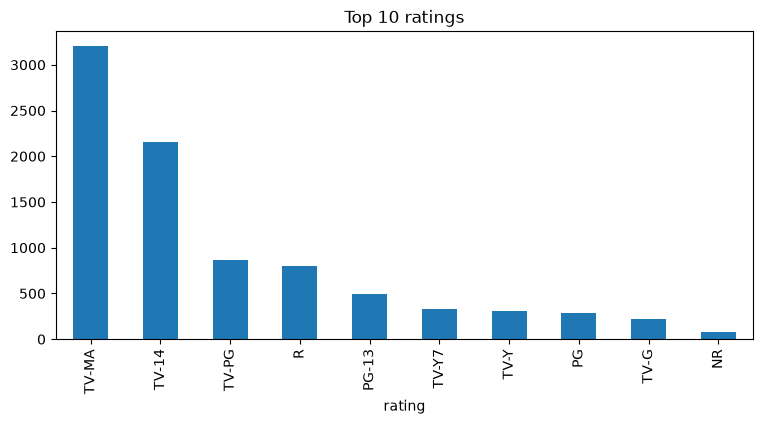

In [34]:
plt.figure(figsize=(9, 4))
df["rating"].value_counts().head(10).plot(kind="bar")
plt.title("Top 10 ratings")
plt.show()

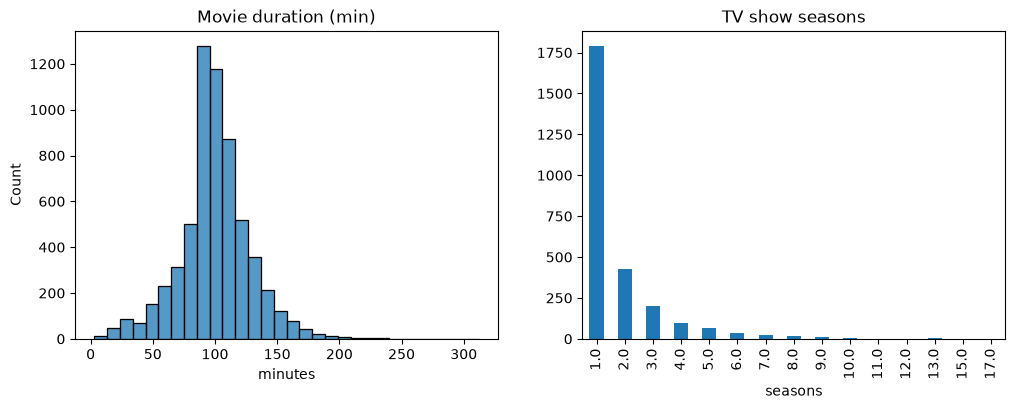

count    6128.000000
mean       99.577187
std        28.290593
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: minutes, dtype: float64


In [35]:
movies = df[df["type"] == "Movie"].copy()
movies["minutes"] = movies["duration"].str.extract(r"(\d+)").astype(float)
shows = df[df["type"] == "TV Show"].copy()
shows["seasons"] = shows["duration"].str.extract(r"(\d+)").astype(float)
 
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(movies["minutes"].dropna(), bins=30, ax=ax[0])
ax[0].set_title("Movie duration (min)")
shows["seasons"].value_counts().sort_index().plot(kind="bar", ax=ax[1])
ax[1].set_title("TV show seasons")
plt.show()
print(movies["minutes"].describe())

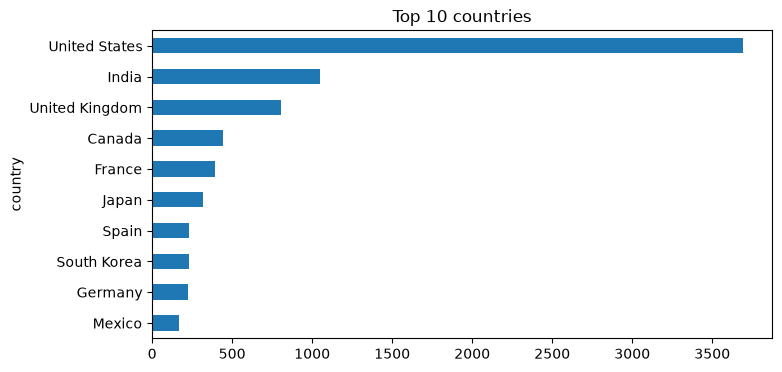

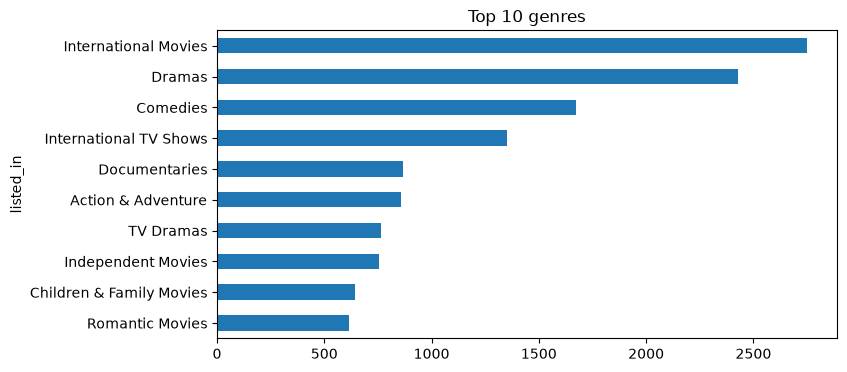

In [36]:
def top_values(col, n=10):
    return (df[col].dropna().str.split(",").explode().str.strip()
              .replace("", pd.NA).dropna().value_counts().head(n))
 
top_values("country").sort_values().plot(kind="barh", figsize=(8, 4), title="Top 10 countries")
plt.show()
top_values("listed_in").sort_values().plot(kind="barh", figsize=(8, 4), title="Top 10 genres")
plt.show()

In [37]:
print(top_values("director"))
print(top_values("cast"))

director
Rajiv Chilaka          22
Jan Suter              21
Raúl Campos            19
Suhas Kadav            16
Marcus Raboy           16
Jay Karas              15
Cathy Garcia-Molina    13
Youssef Chahine        12
Martin Scorsese        12
Jay Chapman            12
Name: count, dtype: int64
cast
Anupam Kher         43
Shah Rukh Khan      35
Julie Tejwani       33
Naseeruddin Shah    32
Takahiro Sakurai    32
Rupa Bhimani        31
Akshay Kumar        30
Om Puri             30
Yuki Kaji           29
Amitabh Bachchan    28
Name: count, dtype: int64


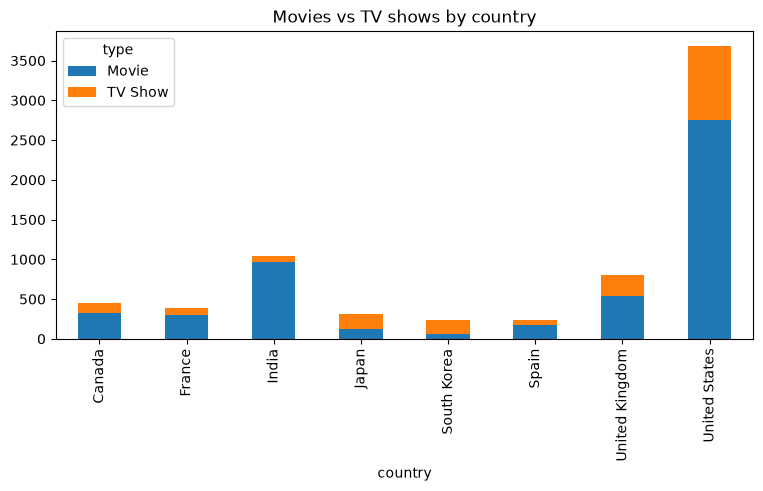

In [38]:
countries = df[["show_id", "type", "country"]].dropna()
countries["country"] = countries["country"].str.split(",")
countries = countries.explode("country").reset_index(drop=True)
countries["country"] = countries["country"].str.strip()
top8 = countries["country"].value_counts().head(8).index
subset = countries[countries["country"].isin(top8)]
pd.crosstab(subset["country"], subset["type"]).plot(kind="bar", stacked=True, figsize=(9, 4))
plt.title("Movies vs TV shows by country")
plt.show()

In [39]:
print(df["lag_years"].describe())
print("Added before release year:", (df["lag_years"] < 0).sum())

count    8797.000000
mean        4.688417
std         8.786998
min        -3.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: lag_years, dtype: float64
Added before release year: 14


In [40]:
df["desc_len"] = df["description"].str.len()
print(df["desc_len"].describe())

count    8807.000000
mean      143.303281
std        10.334959
min        61.000000
25%       140.000000
50%       146.000000
75%       149.000000
max       248.000000
Name: desc_len, dtype: float64


In [41]:
pip install scikit-learn scipy



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [42]:
import itertools
from collections import Counter
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
 
sns.set_theme(style="whitegrid")
df = pd.read_csv("netflix_titles.csv")       # your original file; change the path/name if needed
 
# a) standard names for the multi-value columns
rename = {"listed_in": "genres_raw", "country": "countries_raw",
          "cast": "cast_raw", "director": "director_raw"}
df = df.rename(columns={k: v for k, v in rename.items() if k in df.columns and v not in df.columns})

In [43]:
df["date_added"] = pd.to_datetime(df["date_added"].astype("string").str.strip(), errors="coerce")
if "year_added" not in df:  df["year_added"] = df["date_added"].dt.year
if "month_added" not in df: df["month_added"] = df["date_added"].dt.month
if "years_to_netflix" not in df: df["years_to_netflix"] = df["year_added"] - df["release_year"]
if "decade" not in df:      df["decade"] = (df["release_year"] // 10 * 10).astype(str) + "s"

In [44]:
# c) runtimes that landed in the rating column, then numeric duration columns
shifted = df["rating"].astype("string").str.contains("min", na=False)
df.loc[shifted, "duration"] = df.loc[shifted, "rating"]
df.loc[shifted, "rating"] = np.nan
num = pd.to_numeric(df["duration"].astype("string").str.extract(r"(\d+)")[0], errors="coerce")
if "movie_minutes" not in df: df["movie_minutes"] = num.where(df["type"] == "Movie")
if "tv_seasons" not in df:    df["tv_seasons"] = num.where(df["type"] == "TV Show")
 
# d) audience group from rating
if "audience" not in df:
    aud = {"TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
           "TV-PG": "Older Kids", "PG": "Older Kids", "TV-14": "Teens", "PG-13": "Teens",
           "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults"}
    df["audience"] = df["rating"].map(aud).fillna("Unrated")
 
# e) missing text -> "Unknown", then helper columns
for col in ["director_raw", "cast_raw", "countries_raw"]:
    df[col] = df[col].fillna("Unknown")
if "primary_country" not in df:
    df["primary_country"] = df["countries_raw"].str.split(",").str[0].str.strip().replace("", "Unknown")
if "primary_genre" not in df:
    df["primary_genre"] = df["genres_raw"].str.split(",").str[0].str.strip()
 
# f) list columns used by several cells
df["genre_list"] = df["genres_raw"].str.split(",").apply(lambda xs: [x.strip() for x in xs])
df["country_list"] = df["countries_raw"].str.split(",").apply(
    lambda xs: [x.strip() for x in xs if x.strip()])
 
print(df.shape)
print(df[["genres_raw", "year_added", "movie_minutes", "tv_seasons", "audience", "primary_country"]].isna().sum())
 

(8807, 23)
genres_raw            0
year_added           10
movie_minutes      2676
tv_seasons         6131
audience              0
primary_country       0
dtype: int64


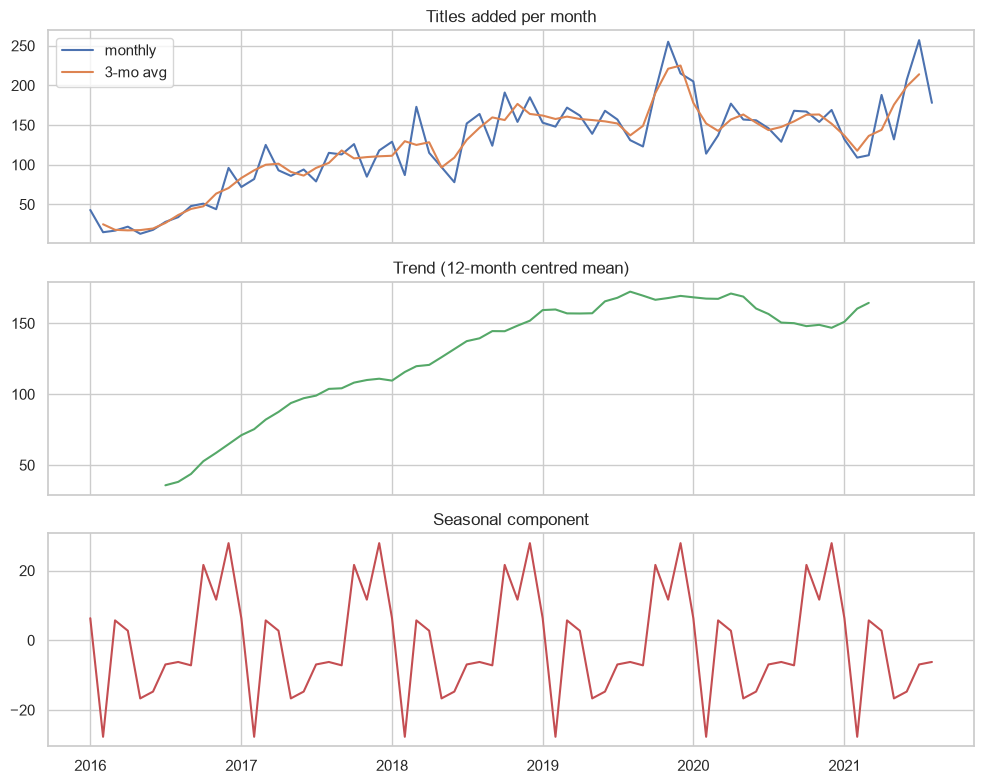

Strongest months: {12: 27.9, 10: 21.6, 11: 11.6}


In [45]:
ts = (df.dropna(subset=["date_added"]).set_index("date_added")
        .resample("MS").size().rename("titles"))["2016":"2021-08"]
trend = ts.rolling(12, center=True).mean()                 # long-term level
resid = ts - trend
seasonal = resid.groupby(resid.index.month).mean()         # typical bump/dip per calendar month
 
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(ts, label="monthly"); ax[0].plot(ts.rolling(3, center=True).mean(), label="3-mo avg")
ax[0].legend(); ax[0].set_title("Titles added per month")
ax[1].plot(trend, color="C2"); ax[1].set_title("Trend (12-month centred mean)")
ax[2].plot(ts.index, ts.index.month.map(seasonal), color="C3"); ax[2].set_title("Seasonal component")
plt.tight_layout(); plt.show()
print("Strongest months:", seasonal.sort_values(ascending=False).head(3).round(1).to_dict())


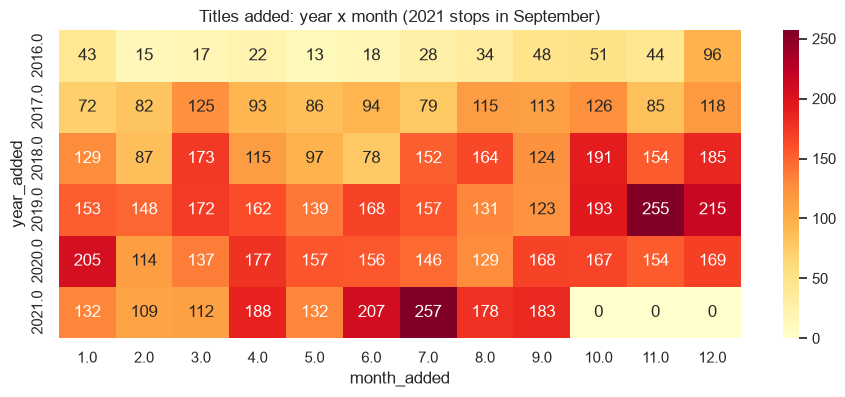

In [46]:
hm = (df.dropna(subset=["date_added"]).query("year_added >= 2016")
        .groupby(["year_added", "month_added"]).size().unstack(fill_value=0))
plt.figure(figsize=(11, 4))
sns.heatmap(hm, annot=True, fmt="d", cmap="YlOrRd")
plt.title("Titles added: year x month (2021 stops in September)"); plt.show()
 

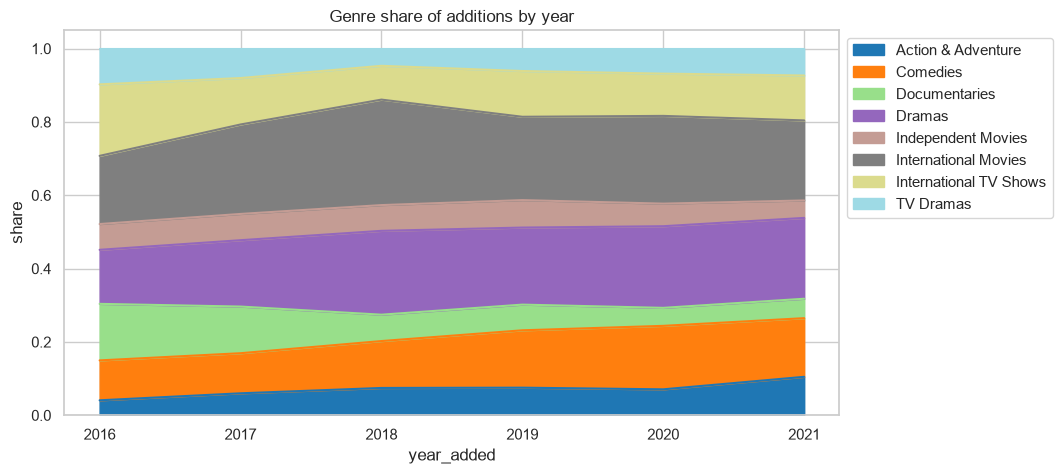

In [47]:
g = df.dropna(subset=["year_added"]).explode("genre_list")
top_genres = g["genre_list"].value_counts().head(8).index
share = (g[g["genre_list"].isin(top_genres) & (g["year_added"] >= 2016)]
         .groupby(["year_added", "genre_list"]).size().unstack(fill_value=0))
share = share.div(share.sum(axis=1), axis=0)
share.plot(kind="area", figsize=(10, 5), cmap="tab20")
plt.title("Genre share of additions by year"); plt.ylabel("share")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1)); plt.show()

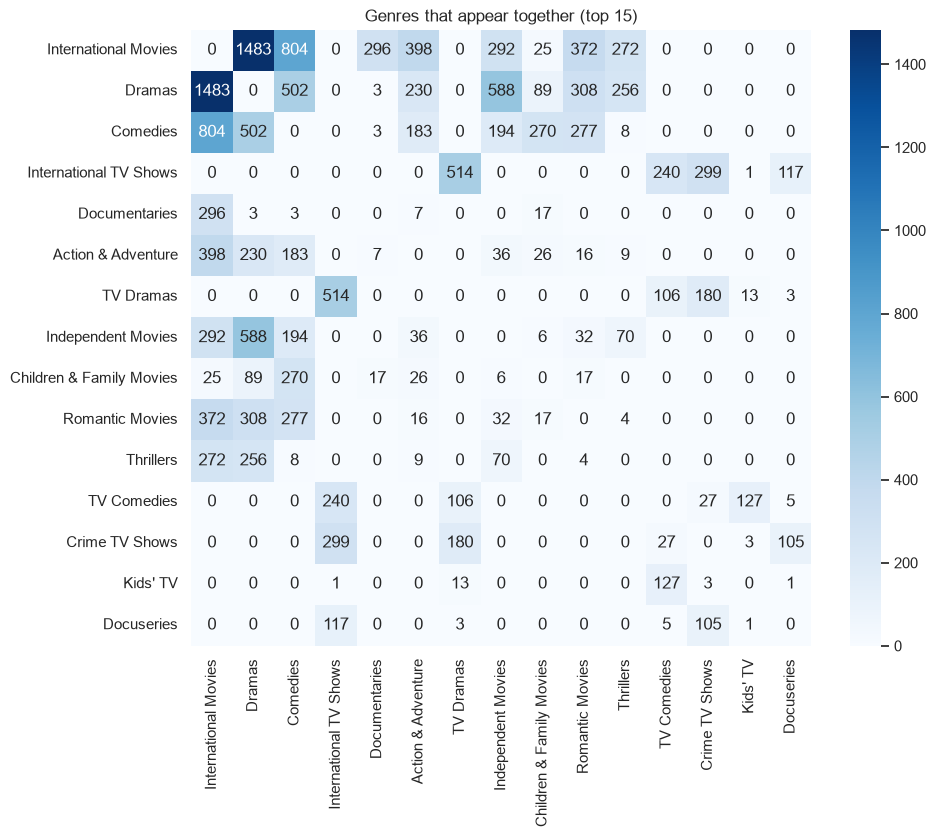

In [48]:
co = Counter()
for gl in df["genre_list"]:
    for a, b in itertools.combinations(sorted(set(gl)), 2):
        co[(a, b)] += 1
top = list(g["genre_list"].value_counts().head(15).index)
mat = pd.DataFrame(0, index=top, columns=top)
for (a, b), n in co.items():
    if a in top and b in top:
        mat.loc[a, b] = mat.loc[b, a] = n
plt.figure(figsize=(10, 8)); sns.heatmap(mat, annot=True, fmt="d", cmap="Blues")
plt.title("Genres that appear together (top 15)"); plt.show()

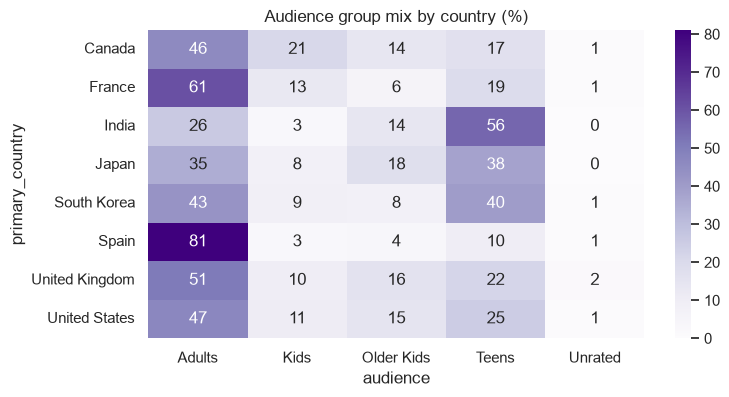

In [49]:
tops = df["primary_country"].value_counts().drop("Unknown", errors="ignore").head(8).index
rc = pd.crosstab(df[df["primary_country"].isin(tops)]["primary_country"],
                 df["audience"], normalize="index") * 100
plt.figure(figsize=(8, 4)); sns.heatmap(rc.round(0), annot=True, fmt=".0f", cmap="Purples")
plt.title("Audience group mix by country (%)"); plt.show()

In [50]:
c = df.dropna(subset=["year_added"]).explode("country_list")
c = c[c["country_list"].notna() & (c["country_list"] != "Unknown")]
hhi = c[c["year_added"] >= 2016].groupby("year_added")["country_list"].apply(
    lambda s: (s.value_counts(normalize=True) ** 2).sum())
print(pd.DataFrame({"HHI": hhi.round(3),
                    "countries": c[c["year_added"] >= 2016].groupby("year_added")["country_list"].nunique()}))
# fastest-growing countries, 2017 -> 2020 (small bases inflate growth, so also show the counts)
cy = c.groupby(["country_list", "year_added"]).size().unstack(fill_value=0)
gr = cy[cy[2020] >= 20][[2017, 2020]].assign(growth=lambda x: (x[2020] - x[2017]) / x[2017].replace(0, np.nan))
print(gr.sort_values("growth", ascending=False).head(10).round(2))

              HHI  countries
year_added                  
2016.0      0.167         52
2017.0      0.140         77
2018.0      0.144         82
2019.0      0.168         72
2020.0      0.160         76
2021.0      0.202         71
year_added     2017.0  2020.0  growth
country_list                         
Nigeria             1      42   41.00
Philippines         1      32   31.00
Indonesia           2      28   13.00
South Africa        5      24    3.80
Japan              37      79    1.14
France             53      97    0.83
United States     462     828    0.79
Germany            33      58    0.76
Brazil             16      27    0.69
Italy              17      28    0.65


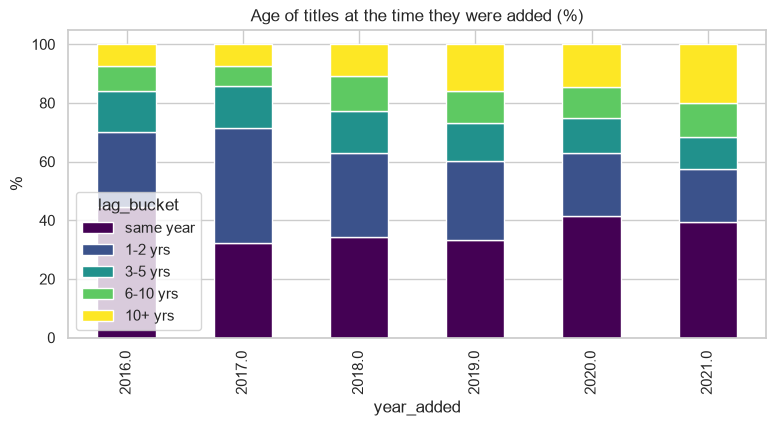

type
Movie      2.0
TV Show    0.0
Name: years_to_netflix, dtype: float64


In [51]:
d = df.dropna(subset=["years_to_netflix"]).query("year_added >= 2016")
d["lag_bucket"] = pd.cut(d["years_to_netflix"], [-5, 0, 2, 5, 10, 100],
                         labels=["same year", "1-2 yrs", "3-5 yrs", "6-10 yrs", "10+ yrs"])
lb = pd.crosstab(d["year_added"], d["lag_bucket"], normalize="index") * 100
lb.plot(kind="bar", stacked=True, figsize=(9, 4), cmap="viridis")
plt.title("Age of titles at the time they were added (%)"); plt.ylabel("%"); plt.show()
print(d.groupby("type")["years_to_netflix"].median())

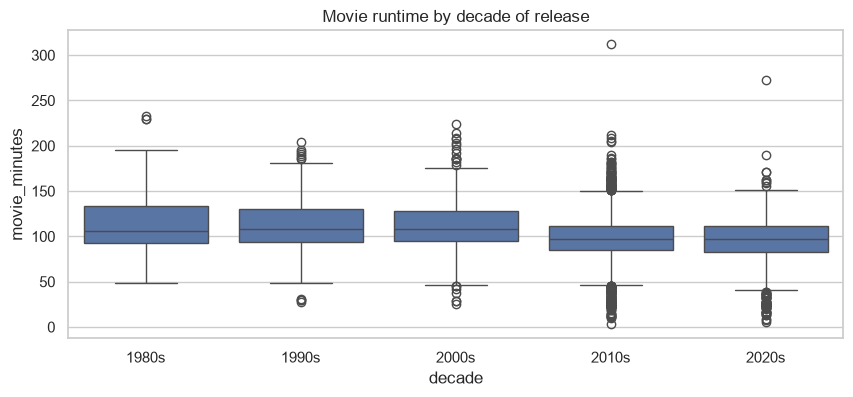

In [52]:
mv = df[(df["type"] == "Movie")].dropna(subset=["movie_minutes"])
recent = mv[mv["release_year"] >= 1980]
plt.figure(figsize=(10, 4))
sns.boxplot(data=recent, x="decade", y="movie_minutes", order=sorted(recent["decade"].unique()))
plt.title("Movie runtime by decade of release"); plt.show()

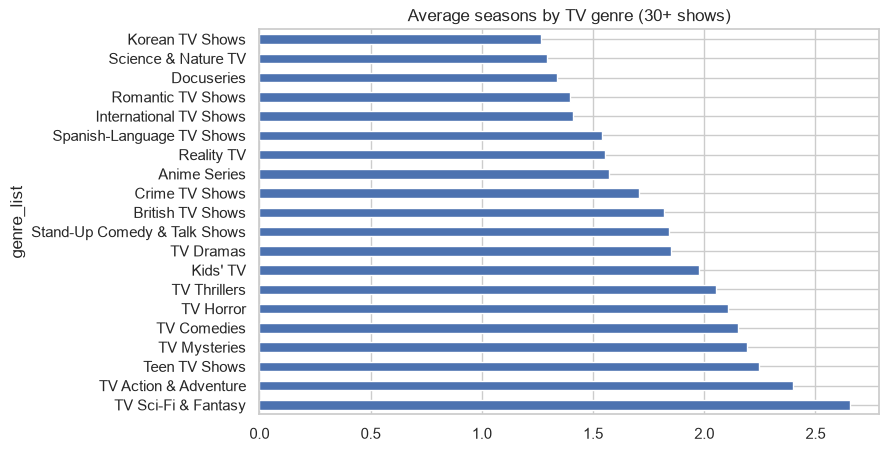

0.67 of TV shows have only 1 season


In [53]:
tv = df[df["type"] == "TV Show"].explode("genre_list")
tvg = (tv.groupby("genre_list")["tv_seasons"].agg(["count", "mean"])
         .query("count >= 30").sort_values("mean", ascending=False))
tvg["mean"].plot(kind="barh", figsize=(8, 5), title="Average seasons by TV genre (30+ shows)")
plt.show()
print((df[df["type"] == "TV Show"]["tv_seasons"] == 1).mean().round(3), "of TV shows have only 1 season")

In [54]:
ct = pd.crosstab(df["type"], df["audience"])
chi2, p, _, _ = stats.chi2_contingency(ct)
print(f"Type vs audience: chi2={chi2:.1f}, p={p:.2e}, Cramer's V={np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))):.2f}")
 
m00 = mv[mv["release_year"] >= 2000]
rho, p = stats.spearmanr(m00["release_year"], m00["movie_minutes"])
print(f"Runtime vs release year (2000+): rho={rho:.3f}, p={p:.3g}")
 
us = mv[mv["primary_country"] == "United States"]["movie_minutes"]
ind = mv[mv["primary_country"] == "India"]["movie_minutes"]
print(f"US median {us.median():.0f} min vs India {ind.median():.0f} min, "
      f"Mann-Whitney p={stats.mannwhitneyu(us, ind)[1]:.3g}")


Type vs audience: chi2=228.0, p=3.47e-48, Cramer's V=0.16
Runtime vs release year (2000+): rho=-0.158, p=7.49e-33
US median 93 min vs India 127 min, Mann-Whitney p=9.35e-217


In [55]:
q1, q3 = mv["movie_minutes"].quantile([.25, .75])
iqr = q3 - q1
out = mv[(mv["movie_minutes"] < q1 - 1.5 * iqr) | (mv["movie_minutes"] > q3 + 1.5 * iqr)]
print(f"{len(out)} outliers; longest:")
print(out.nlargest(5, "movie_minutes")[["title", "movie_minutes", "release_year"]])

450 outliers; longest:
                            title  movie_minutes  release_year
4253   Black Mirror: Bandersnatch            312          2018
717   Headspace: Unwind Your Mind            273          2021
2491       The School of Mischief            253          1973
2487               No Longer kids            237          1979
2484           Lock Your Girls In            233          1982


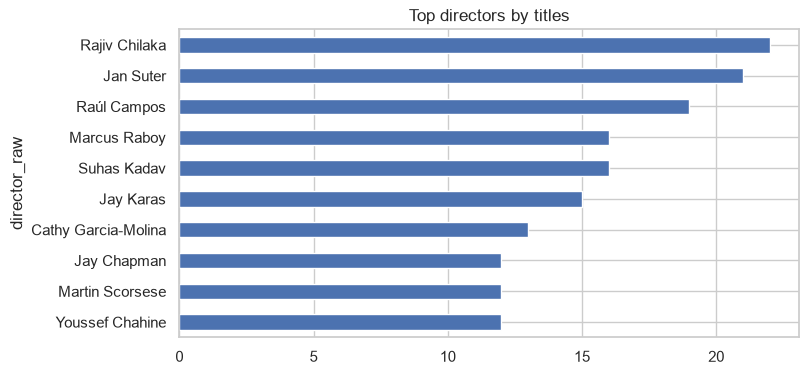

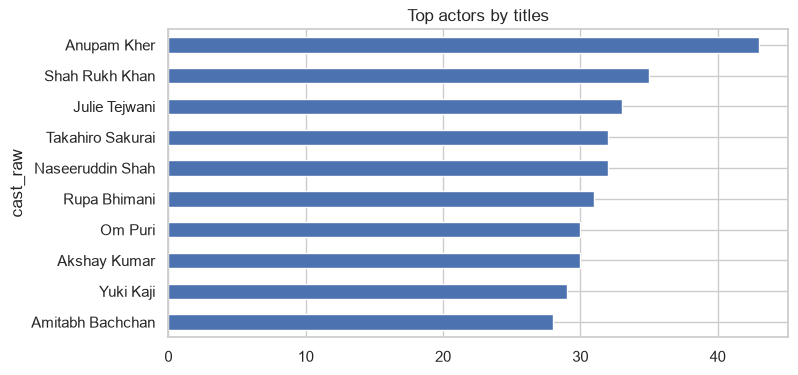

In [56]:
def top_people(col, n=10):
    s = df.loc[df[col] != "Unknown", col].str.split(",").explode().str.strip()
    return s.value_counts().head(n)
 
top_people("director_raw").sort_values().plot(kind="barh", figsize=(8, 4), title="Top directors by titles")
plt.show()
top_people("cast_raw").sort_values().plot(kind="barh", figsize=(8, 4), title="Top actors by titles")
plt.show()

In [57]:
pairs = Counter()
for cast in df.loc[df["cast_raw"] != "Unknown", "cast_raw"]:
    names = sorted({n.strip() for n in cast.split(",")})
    for a, b in itertools.combinations(names[:10], 2):      # first 10 billed, keeps it fast
        pairs[(a, b)] += 1
print(pd.DataFrame(pairs.most_common(10), columns=["pair", "titles together"]))

                              pair  titles together
0    (Julie Tejwani, Rupa Bhimani)               31
1     (Julie Tejwani, Rajesh Kava)               24
2      (Rajesh Kava, Rupa Bhimani)               22
3  (Jigna Bhardwaj, Julie Tejwani)               21
4    (Jigna Bhardwaj, Rajesh Kava)               20
5   (Jigna Bhardwaj, Rupa Bhimani)               20
6   (Jigna Bhardwaj, Vatsal Dubey)               18
7    (Julie Tejwani, Vatsal Dubey)               18
8     (Rupa Bhimani, Vatsal Dubey)               18
9      (Rajesh Kava, Vatsal Dubey)               17


In [58]:
miss = df[["director_raw", "cast_raw", "countries_raw"]].eq("Unknown")
print(miss.groupby(df["type"]).mean().round(3))
print("Director missing by audience:\n", miss["director_raw"].groupby(df["audience"]).mean().round(3))

         director_raw  cast_raw  countries_raw
type                                          
Movie           0.031     0.077          0.072
TV Show         0.914     0.131          0.146
Director missing by audience:
 audience
Adults        0.273
Kids          0.552
Older Kids    0.283
Teens         0.266
Unrated       0.089
Name: director_raw, dtype: float64


          count  mean  std   min   25%   50%   75%   max
type                                                    
Movie    6131.0  24.1  2.9  10.0  22.0  24.0  26.0  48.0
TV Show  2676.0  23.5  2.7  12.0  22.0  24.0  25.0  35.0


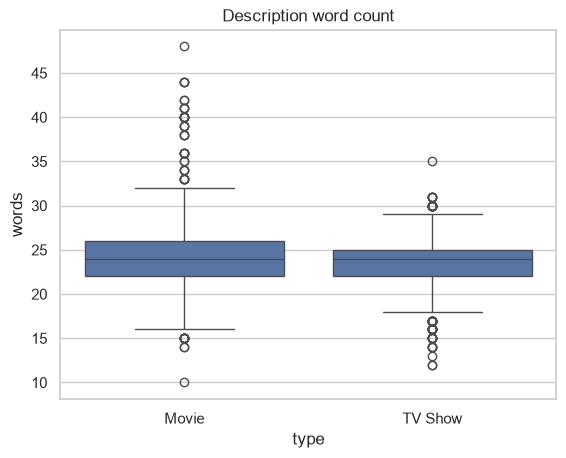

In [59]:
df["words"] = df["description"].str.split().str.len()
print(df.groupby("type")["words"].describe().round(1))
sns.boxplot(data=df, x="type", y="words"); plt.title("Description word count"); plt.show()

In [62]:
# drop the list columns (they'd be saved as messy text) and the helper columns
clean = df.drop(columns=["genre_list", "country_list", "desc_len", "words"], errors="ignore")

clean.to_csv("netflix_titles_cleaned.csv", index=False, encoding="utf-8-sig")
print(clean.shape)

(8807, 21)


In [63]:
out = df.drop(columns=["genre_list", "country_list", "desc_len", "words"], errors="ignore").copy()

# keep year/month as whole numbers (otherwise they save as 2019.0)
for c in ["year_added", "month_added", "years_to_netflix"]:
    out[c] = out[c].astype("Int64")

out.to_csv("netflix_cleaned.csv", index=False, encoding="utf-8-sig")

# bridge tables so genres and countries can be charted properly
genres = df[["show_id", "genre_list"]].explode("genre_list").rename(columns={"genre_list": "genre"})
countries = df[["show_id", "country_list"]].explode("country_list").rename(columns={"country_list": "country"})
genres.dropna().to_csv("netflix_genres.csv", index=False, encoding="utf-8-sig")
countries.dropna().to_csv("netflix_countries.csv", index=False, encoding="utf-8-sig")